# Exercise 13 – Monte Carlo at finite temperature

**Week 3 · Monte Carlo and optimisation of clusters**

Allowing uphill moves with probability $e^{-\Delta E/k_BT}$ lets the atoms
escape shallow minima. We run Metropolis Monte Carlo at $k_BT = 0.15$ for a
three-atom system and for small clusters bound to one fixed atom (orange).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.atoms import Cluster, LennardJones, mc_quench, random_positions

rng = np.random.default_rng(0)
calc = LennardJones()


def before_after(cluster, n_sweeps, step, kT, lims, size):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
    cluster.draw(axes[0], size=size)
    path = mc_quench(cluster, n_sweeps=n_sweeps, step=step, kT=kT, rng=rng)
    cluster.draw(axes[1], size=size)
    for ax, title in zip(axes, ["start", "after Monte Carlo"]):
        ax.set(xlim=lims, ylim=lims)
        ax.set_title(f"{title}: {ax.get_title()}")
        ax.grid(True, alpha=0.4)
    fig.tight_layout()
    plt.show()
    print(f"{len(path) - 1} accepted moves")

## Two mobile atoms next to a fixed one

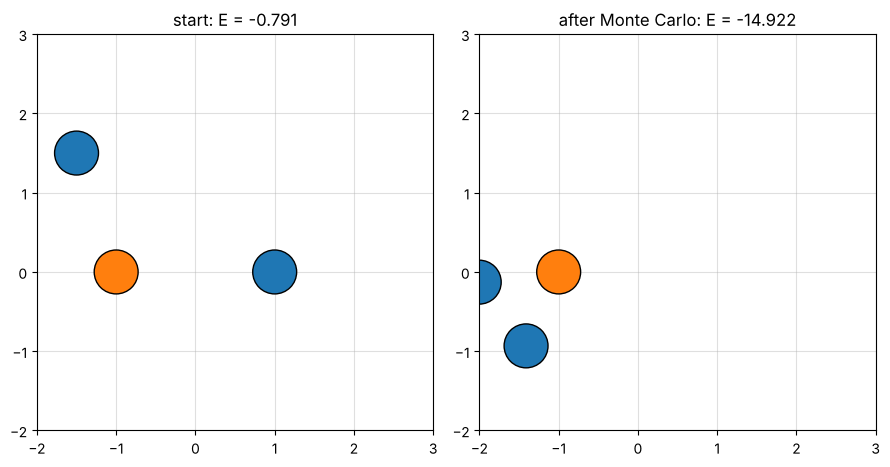

10132 accepted moves


In [2]:
before_after(Cluster(calc, [[-1, 0], [1, 0], [-1.5, 1.5]], static=[True, False, False]),
             n_sweeps=20_000, step=0.05, kT=0.15, lims=(-2, 3), size=1000)

## Five and six atoms around a fixed atom

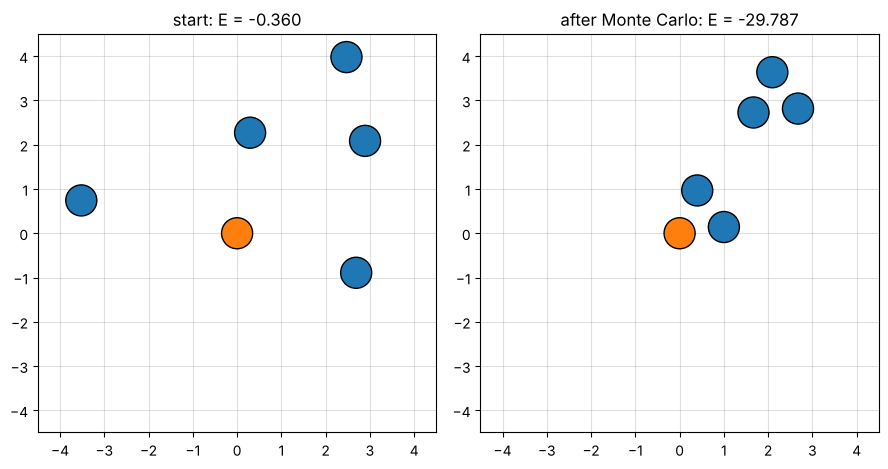

867 accepted moves


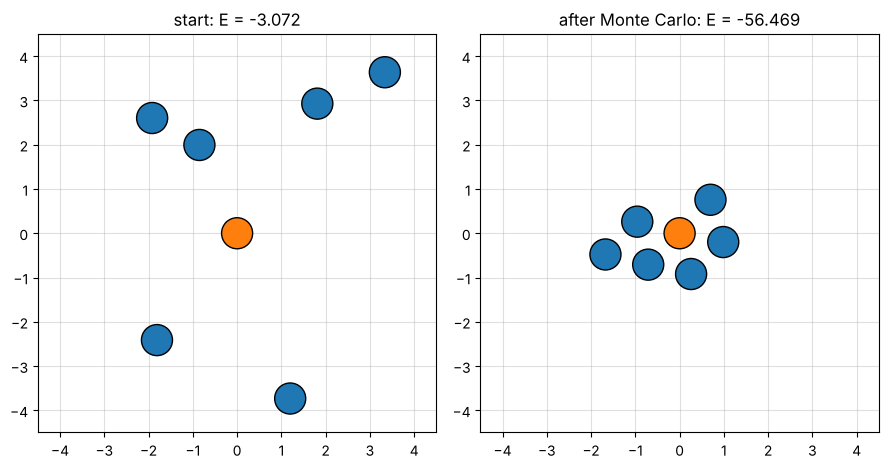

1802 accepted moves


In [3]:
for n in [5, 6]:
    start = np.vstack([random_positions(n, 4, min_distance=0.8, rng=rng), [[0, 0]]])
    before_after(Cluster(calc, start, static=[False] * n + [True]),
                 n_sweeps=5_000, step=0.2, kT=0.15, lims=(-4.5, 4.5), size=500)

The atoms find each other and form compact, mostly triangular arrangements,
but at this temperature they do not always all attach to the fixed atom or
reach the global minimum – fragments far apart have no force pulling them
together.